In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [2]:
# find genes that are always change or stable
# in both HEK-HCT vs HCT-HEK
df1 = pd.read_csv("../../result/HEK293T_HCT116/coemb/promergeclub_HCT116anchor/HEK293T/HEK293T_specific_score.tsv", sep="\t", index_col=0)
df2 = pd.read_csv("../../result/HEK293T_HCT116/coemb/promergeclub_HEK293Tanchor/HCT116/HCT116_specific_score.tsv", sep="\t", index_col=0)
df = df1['specific_score'].rank(ascending=False) + df2['specific_score'].rank(ascending=False)
df = df.sort_values().dropna()

In [3]:
# top 10%
print("\n".join(df.iloc[:int(len(df) * 0.1)].index))

BMAL1
SCGB1D2
BMAL2
S100PBP
TMEM44
NPAS2
PLEKHA7
CIDEB
CCDC185
LRG1
CHIT1
SYT1
APOE
ZDHHC21
TSPAN33
ZNF749
SYT5
IL13
STMN3
GJA8
NEDD8-MDP1
SYT2
FCN1
C9
SNAPC2
SLC25A18
CIPC
AFM
ADAR
PBLD
KLK4
SMR3B
PRELID3A
CYCS
PCED1B
PRSS45P
ATPSCKMT
MAGEB10
CRYGN
ARHGEF35
P2RX6
UBE2U
CNTRL
TTC21B
NCF2
FCN2
PLAAT4
CDK18
ROBO3
TMEM150A
CEP15
SPATA4
PTPN2
WDR19
IFNA6
ZNF321P
FERMT3
TPH1
SRR
ZDHHC23
CASTOR1
SHD
APOF
LIMK1
RNASE4
FAM184A
CC2D2A
LSP1
OR2A4
IFNA7
SLC25A51
THAP8
PHF8
ST3GAL2
CLDN20
CKLF
KLK10
WTAP
TMTC4
NCF1
UVRAG
SNAPC1
SPNS3
IFNA1
CFI
PGLYRP1
SLC25A21
UBA52
NSG2
SSH1
CMC2
FCRL2
SPRY4
CRYGD
HERC3
CARTPT
C12orf43
CHI3L1
AGMAT
GINM1
ABHD5
RAB17
FAM153B
MOG
TAGLN3
CA4
B4GALT7
ADH1C
COL1A2
DNAAF4
KLHDC9
SLC47A1
UBTD2
FYN
TMEM140
COL2A1
IFNA5
TMEM53
CD55
SLAMF8
MUC7
SLC25A52
ATAT1
ZDHHC16
IQUB
ATP7B
CORT
AKNAD1
NXT1
TTBK2
TNNI3
KIR3DL1
RNF144A
FCGR3A
MAS1
LPIN1
GGNBP2
TESC
HOXB4
ABCA8
PLPPR4
CYGB
HTRA1
DDX3Y
BOLA3
SYT10
FRMD4B
CER1
DNAJC27
ARHGEF17
EFNB2
PLXNC1
AGT
STK36
COX11
IGHD
POPDC1
CRYGB

In [4]:
# bottom 10%
print("\n".join(df.iloc[-int(len(df) * 0.1):].index))

ACTB
DLGAP4
EBNA1BP2
SEPTIN10
CCNC
ZFC3H1
FH
IFT74
DARS1
RNF31
CCNE1
ARMC8
PMFBP1
DTL
MT-CO1
RMP64
CHTF8
RBM7
SF3B3
GNLY
TFEB
LHX4
SUPT16H
NPM1
RBM28
SH3BGRL
BET1
RPS6
CDK5
RPS15
NSMCE3
PRKRA
ATG16L2
PRRC2B
NCK2
SUMO2
H2BC12
TUT7
POFUT4
TCP1
ADRM1
WDR3
NDUFA6
XRCC6
TRIM39
ATP5MG
PKD1
GGA3
EXOC2
BHLHE40
NDUFAF1
ITGA7
GRK2
VPS26A
ACTR6
RNF111
NFKBIB
ATP6V1A
RGPD1
AMOTL1
PSMD8
AP1S1
RRP1B
ZHX2
INTS10
FBXO7
DHX30
DPYSL2
MCM6
DAXX
EXOC7
KPNA3
NUP93
MPP3
UTRN
ZC3H8
NOSIP
MIX23
CCNK
CEBPZ
GPN1
MICAL3
CDCA2
ADPRS
SCFD1
TENT4B
PHF12
ATP5F1A
PSMC4
SRSF7
ZER1
FAM20B
NUP205
NLN
HTATIP2
NLGN2
TECR
ID1
PSMC2
IBTK
TARDBP
KMT2A
XRCC5
TBL1Y
UBA2
NUP58
KLHDC3
MAN2A2
RSL1D1
ARHGAP17
POLR3A
CCNA2
NMI
PHC2
ATP5PD
TECPR1
CISH
EGFR
EXOC5
TBC1D10B
B2M
YBX3
EXOSC3
EEF1A1
SEPTIN7
CUL2
PPP1CB
RMND5A
PLXNA3
STRN
SNRPGP15
RFC2
NME7
PSMD1
CDC27
SEC62
DDX21
BTG3
NIBAN1
TSHZ1
SON
ATXN7
NOC3L
NIT2
BLOC1S3
ACTR3B
GAR1
ZNF22
YEATS4
EIF3J
COG5
WDR26
RSBN1L
NEMF
JMJD6
EEF1E1
CTCF
RAN
WASF1
SMC6
PHF23
EMC6
IFT57
ANAPC2
FOS

### GO enrichment of the two above gene sets
GO enrichment is done in gprofiler website version,  
https://biit.cs.ut.ee/gprofiler/gost  
Default settings but keep only GOMF and GOBP source.  
Download csv into `../../result/HEK293T_HCT116/gprofiler/`  
with names `top.csv` and `bottom.csv`

### plot result

In [5]:
enrichment1 = pd.read_csv("../../result/HEK293T_HCT116/gprofiler/top.csv", sep=",")
enrichment1 = enrichment1.sort_values("negative_log10_of_adjusted_p_value", ascending=False)
list_MF = enrichment1[(enrichment1['highlighted'] == True) & (enrichment1['source'] == "GO:MF")].iloc[:5].index.tolist()
list_BP = enrichment1[(enrichment1['highlighted'] == True) & (enrichment1['source'] == "GO:BP")].iloc[:5].index.tolist()
enrichment1 = (enrichment1.loc[list_MF+list_BP]).sort_values(["source", "negative_log10_of_adjusted_p_value"], ascending=False).reset_index(drop=True)

In [6]:
enrichment2 = pd.read_csv("../../result/HEK293T_HCT116/gprofiler/bottom.csv", sep=",")
enrichment2 = enrichment2.sort_values("negative_log10_of_adjusted_p_value", ascending=False)
list_MF = enrichment2[(enrichment2['highlighted'] == True) & (enrichment2['source'] == "GO:MF")].iloc[:5].index.tolist()
list_BP = enrichment2[(enrichment2['highlighted'] == True) & (enrichment2['source'] == "GO:BP")].iloc[:5].index.tolist()
enrichment2 = (enrichment2.loc[list_MF+list_BP]).sort_values(["source", "negative_log10_of_adjusted_p_value"], ascending=False).reset_index(drop=True)

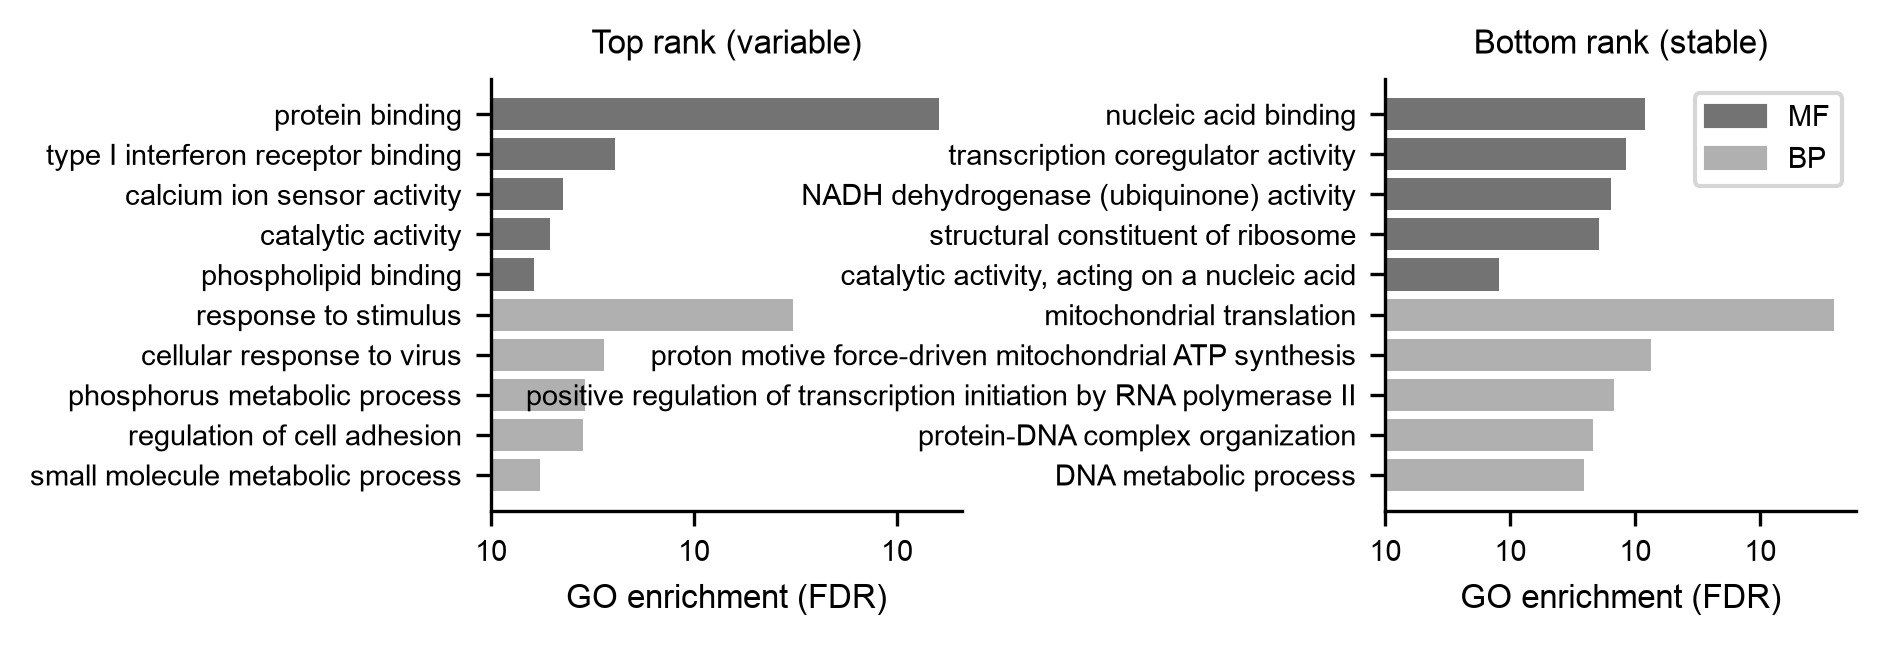

In [7]:
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, axes = plt.subplots(
    nrows=1, ncols=2,
    sharex=False, sharey=False,
    gridspec_kw={"hspace":0, "wspace":0.9},
    figsize=(6.5, 2), dpi=300
)
fig.subplots_adjust(left=0.28, right=0.98, bottom=0.18, top=0.9)

axes[0].barh(
    range(enrichment1.shape[0]),
    enrichment1['negative_log10_of_adjusted_p_value'][::-1],
    color=['#b0b0b0']*5 + ['#737373']*5,
)
axes[0].set_xlabel("GO enrichment (FDR)", fontsize=8)
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_yticks(range(enrichment1.shape[0]), labels=enrichment1['term_name'].values[::-1])
axes[0].set_xticks([0, 10, 20], labels=[10, 10, 10])
axes[0].set_title("Top rank (variable)", fontsize=8)

axes[1].barh(
    range(enrichment2.shape[0]),
    enrichment2['negative_log10_of_adjusted_p_value'][::-1],
    color=['#b0b0b0']*5 + ['#737373']*5,
)
axes[1].set_xlabel("GO enrichment (FDR)", fontsize=8)
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].set_yticks(range(enrichment2.shape[0]), labels=enrichment2['term_name'].values[::-1])
axes[1].set_xticks([0, 20, 40, 60], labels=[10, 10, 10, 10])
axes[1].set_title("Bottom rank (stable)", fontsize=8)

grey_patch = mpatches.Patch(color='#737373', label='MF')
dark_patch = mpatches.Patch(color='#b0b0b0', label='BP')
plt.legend(handles=[grey_patch, dark_patch], loc='best')

plt.savefig("./fig3_go.pdf", bbox_inches='tight', transparent=True)